Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
First 5 rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   

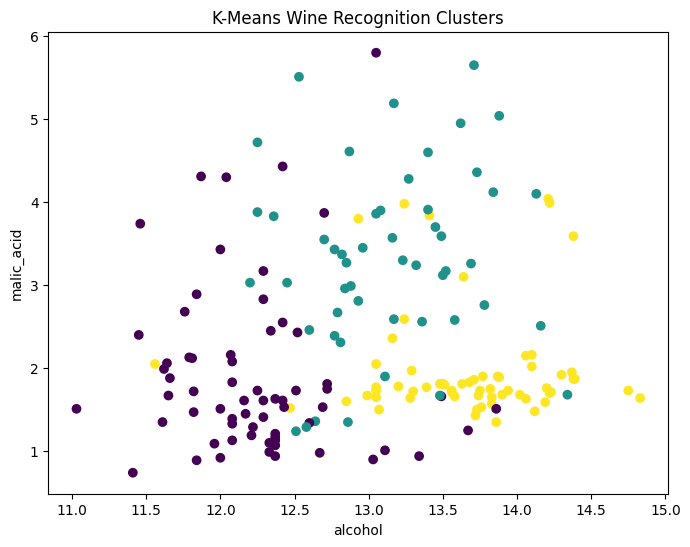


Explained Variance:
[0.36198848 0.1920749 ]

Total Variance Explained:
0.5540633835693527


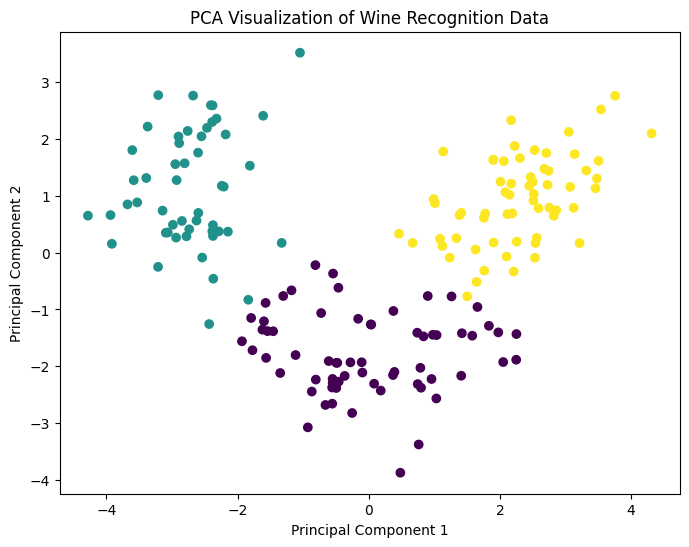

In [ ]:
# ============================================
# K-Means and PCA

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA


# ============================================
# 2. Mount Google Drive
# ============================================

drive.mount('/content/drive')


# ============================================
# 3. Read the Kaggle dataset
# ============================================


file_path = "/content/drive/MyDrive/Datasets/WineRecognition.csv"


df = pd.read_csv(file_path)

print("First 5 rows:")
print(df.head())


# ============================================
# 4. Select features
# ============================================

X = df[
    [
        "alcohol",
        "malic_acid",
        "ash",
        "alcalinity_of_ash",
        "magnesium",
        "total_phenols",
        "flavanoids",
        "nonflavanoid_phenols",
        "proanthocyanins",
        "color_intensity",
        "hue",
        "od280/od315_of_diluted_wines",
        "proline"
        ]
    ]

print("\nSelected Features:")
print(X.head())


# ============================================
# 5. Standardize the data
# ============================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================
# 6. K-MEANS CLUSTERING
# ============================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means Results:")
print(df[
    [
        "alcohol",
        "malic_acid",
        "ash",
        "alcalinity_of_ash",
        "magnesium",
        "total_phenols",
        "flavanoids",
        "nonflavanoid_phenols",
        "proanthocyanins",
        "color_intensity",
        "hue",
        "od280/od315_of_diluted_wines",
        "proline",
        'KMeans_Cluster'
    ]
].head(10))


# ============================================
# 7. Plot K-Means
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df["alcohol"],
    df["malic_acid"],
    c=df['KMeans_Cluster']
)

plt.xlabel("alcohol")
plt.ylabel("malic_acid")
plt.title('K-Means Wine Recognition Clusters')

plt.show()


# ============================================
# 10. PCA
# ============================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


# Add PCA results to DataFrame
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]


# ============================================
# 11. Explained Variance
# ============================================

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())


# ============================================
# 12. Plot PCA
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df['PC1'],
    df['PC2'],
    c=df['KMeans_Cluster']
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Visualization of Wine Recognition Data')

plt.show()

PART 1:



Dataset Name: Sales Data



Description: The data represents a multitude of customer sales with specific features to represent each transaction.



There are 2824 rows and 8 USED columns



PART 3:



Features: ORDERNUMBER,  QUANTITYORDERED,  PRICEEACH,  ORDERLINENUMBER, SALES,QTR_ID,  MONTH_ID, YEAR_ID



Reasoning: First the string based features were eliminated because they do not contribute to the overall results. Each of the remaining features helps the clusters be more precise in how total sales is being achieved. Quantity and Price especially help determine how the sales should be clustered. The others have a much smaller impact, but things like what quarter it currently is also contribute to sales results.



Standardization: This is important since it helps the scale of features to remain relevant. For something like sales, it is obviously a very important feature, but it is almost equally important to quantity, but sales numbers will be in the thousands, distorting the results. By standardizing, it makes sure each feature is weighted as much as it should be.



PART 4:



Number of Clusters: I chose 6 clusters since there are a relatively large amount of data points and it needed to be able to compensate for groupings out on the far right of the graph. It also allowed more distinction for middle points that were grouped extremely close so you can see some outliers up/down from the middle points.



Cluster Representation: Each separate cluster represents how individual unit prices influence the total sales. The quantity has an impact on the clusters, but mainly they are determining how price per product is likely to change total sales.



PART 5:



Number of Clusters: Again it is set to 6 clusters to keep similarity with k-means clusters.



Comparison to K-Means: Hierarchical clusters are more scattered around, while k-means has structured groups. Generally there are less outliers within specific k-means groups where hierarchical has groups that may cover the entire graph.



PART 6:



PCA Explanation: Only around 50% of the information (variance) is retained through the PCA graph. The clusters here are also very organized and each cluster looks to be split into mini clusters close to each other. There are a lot of places where clusters overlap as well, which tracks with the other clustering from the previous two graphs. Finally, since each PC takes a conglomeration of the total data, all the points are more trended to the center, rather than the gradual increase from left to right like the other two were.



PART 7:



What K-Means Revealed: As the price per product increased, the general trend was that sales would also increase, with quantity being a smaller influence overall. This changes at the max (100) value which had points from almost every cluster in the k-means graph.



What Hierarchical Revealed: Provided more context for other features by showing more spread out groupings. The other features influence the clusters more in hierarchical because of the tree like structure which is why data points are further apart in many areas of the graph.



How Much Variation With PC1/PC2: The first captured 31%, the second was 23%.



What PCA Was Helpful With: PCA allowed for a cleaner look at the groupings since it condensed everything into just two variables. It also showed the massive overlaps that were present in the previous two graphs, but more clustered in the center instead of a mess along the entire graph.

